# RQ7: Can weather predict music mood — and power song recommendations?

**Question:** Can daily weather attributes (precipitation, sunshine, temperature) predict the mood of the music people listen to (valence, energy, danceability, tempo), and can the predicted mood profile be used to recommend songs?

This notebook is a **reporting layer**: it reads the outputs produced by the `Workflow 7` Snakemake pipeline and adds interpretation. It does **not** recompute anything; the analysis lives in the tested CLI components `datapreprocessing_w7.py` (feature engineering), `train_model.py` (train + compare models, then recommend), and `plot_results.py` (feature-importance chart).

## Method (in brief)

**Preprocessing — feature engineering.** We run a standalone preprocessing script to dynamically derive calendar indicators (`is_weekend`, `day_of_week`, `month`) and match German public holidays (`is_holiday`) using the holidays library.

**Part A — predict mood from weather.** For each mood target (`avg_valence`, `avg_energy`, `avg_danceability`, `avg_tempo`) we train and compare several regressors (`random_forest_depth5`, `random_forest_depth15`, `ridge`, `hist_gradient_boosting`) on weather + calendar features, using an 80/20 train/test split. Models are compared on held-out **R²** and **MAE**, and the model type with the best mean R² across all four targets is selected.

**Feature importances** for the winning model are plotted as a 2×2 grid, one panel per mood target — the method depends on the model type: mean decrease in impurity (variance reduction) for `RandomForestRegressor` (both depths), raw coefficients for `Ridge`, and permutation importance (computed on the full processed dataset, not a held-out split) for `HistGradientBoostingRegressor` (which exposes neither of the other two natively).

**Part B — recommend songs.** The winning models predict a mood profile from a custom configuration YAML file (`configuration_w7.yaml`). A `MinMaxScaler` + k-NN index built over the song catalog's audio features finds the closest matches. Distance ties are systematically broken using a secondary sort on track popularity to guarantee 100% reproducible recommendations.

## How to reproduce

```bash
snakemake --cores 1 results/workflow_7/song_recommendations.csv results/workflow_7/feature_importances.png
```

This orchestrates the RQ7 pipeline stages (`workflow/rules/rq7.smk`, included from the project-root `workflow/Snakefile`) and regenerates `results/workflow_7/weather_metrics.csv`, `results/workflow_7/weather_model.pkl`, `results/workflow_7/feature_importances.png`, and `results/workflow_7/song_recommendations.csv`, which the cells below load.

In [2]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

# If the notebook runs from inside src/Workflow 7, go up two levels to reach project root
RESULTS = Path("../../results/workflow_7")
if not RESULTS.exists():
    RESULTS = Path("../results/workflow_7")  # Alternative fallback path

comparison_df = pd.read_csv(RESULTS / "weather_metrics.csv")
print(f"{comparison_df['model'].nunique()} model types compared across {comparison_df['target'].nunique()} mood targets")

pivot = comparison_df.pivot(index="target", columns="model", values=["r2", "mae"])
pivot

4 model types compared across 4 mood targets


r2                        \
model            hist_gradient_boosting random_forest_depth15   
target                                                          
avg_danceability               0.009538              0.028948   
avg_energy                     0.255550              0.252186   
avg_tempo                      0.014137             -0.001387   
avg_valence                    0.062533              0.081586   

                                                                   mae  \
model            random_forest_depth5     ridge hist_gradient_boosting   
target                                                                   
avg_danceability             0.036643  0.014722               0.015062   
avg_energy                   0.268621  0.151304               0.019207   
avg_tempo                    0.032341  0.003411               3.674153   
avg_valence                  0.068155  0.005589               0.024730   

                                                                       
model            random_forest_depth15 random_forest_depth5     ridge  
target                                                                 
avg_danceability              0.014915             0.014960  0.015220  
avg_energy                    0.019105             0.019289  0.020620  
avg_tempo                     3.633999             3.686231  3.759526  
avg_valence                   0.024371             0.024483  0.025306

In [3]:
# Best model type overall, by mean R2 across all four mood targets
mean_r2_by_model = comparison_df.groupby("model")["r2"].mean().sort_values(ascending=False)
best_model_name = mean_r2_by_model.index[0]

print(f"Best model by mean R2 across targets: {best_model_name} (mean R2={mean_r2_by_model.iloc[0]:.4f})")
display(mean_r2_by_model.to_frame("mean_r2"))

Best model by mean R2 across targets: random_forest_depth5 (mean R2=0.1014)


,mean_r2
model,
random_forest_depth5,0.101440
random_forest_depth15,0.090334
hist_gradient_boosting,0.085439
ridge,0.043757


## Feature importance

Which weather/calendar features drive each mood prediction for the winning model.

**How to read this:** each of the 4 panels below is one mood target (`avg_valence`, `avg_energy`, `avg_danceability`, `avg_tempo`), with bars ranked by how much each feature contributes to that target's prediction.

- For a **`RandomForestRegressor` winner** (`depth5`/`depth15`): bars show **mean decrease in impurity** — how much a feature reduces variance across the model's splits (regression trees split on variance reduction, not Gini impurity — "Gini importance" is a classification-tree term), scaled 0–1 and summing to 1 across all features for a given target. Higher = the model relied on that feature more to make its splits.
- For a **`Ridge` winner**: bars instead show **raw regression coefficients** — the signed weight on each feature *as-is* (features are **not** standardized before fitting in `train_model.py`), so coefficients aren't directly comparable across features on very different scales (e.g. `month` 1–12 vs. `is_weekend` 0/1). Unlike the tree-based importances these can be negative, so bars are ranked by absolute magnitude rather than raw value, and there's no fixed 0–1 scale.
- For a **`HistGradientBoostingRegressor` winner**: this model exposes neither of the above natively, so bars show **permutation importance** instead — how much R² drops when a feature's values are randomly shuffled, computed on the full processed dataset supplied to `plot_results.py` (not a held-out test split). Like coefficients, this can be negative (shuffling a genuinely unhelpful feature can occasionally *improve* the score by chance), so there's no fixed 0–1 scale here either.

Since `random_forest_depth5` won this run (see the model comparison above), the chart below shows mean-decrease-in-impurity importances.

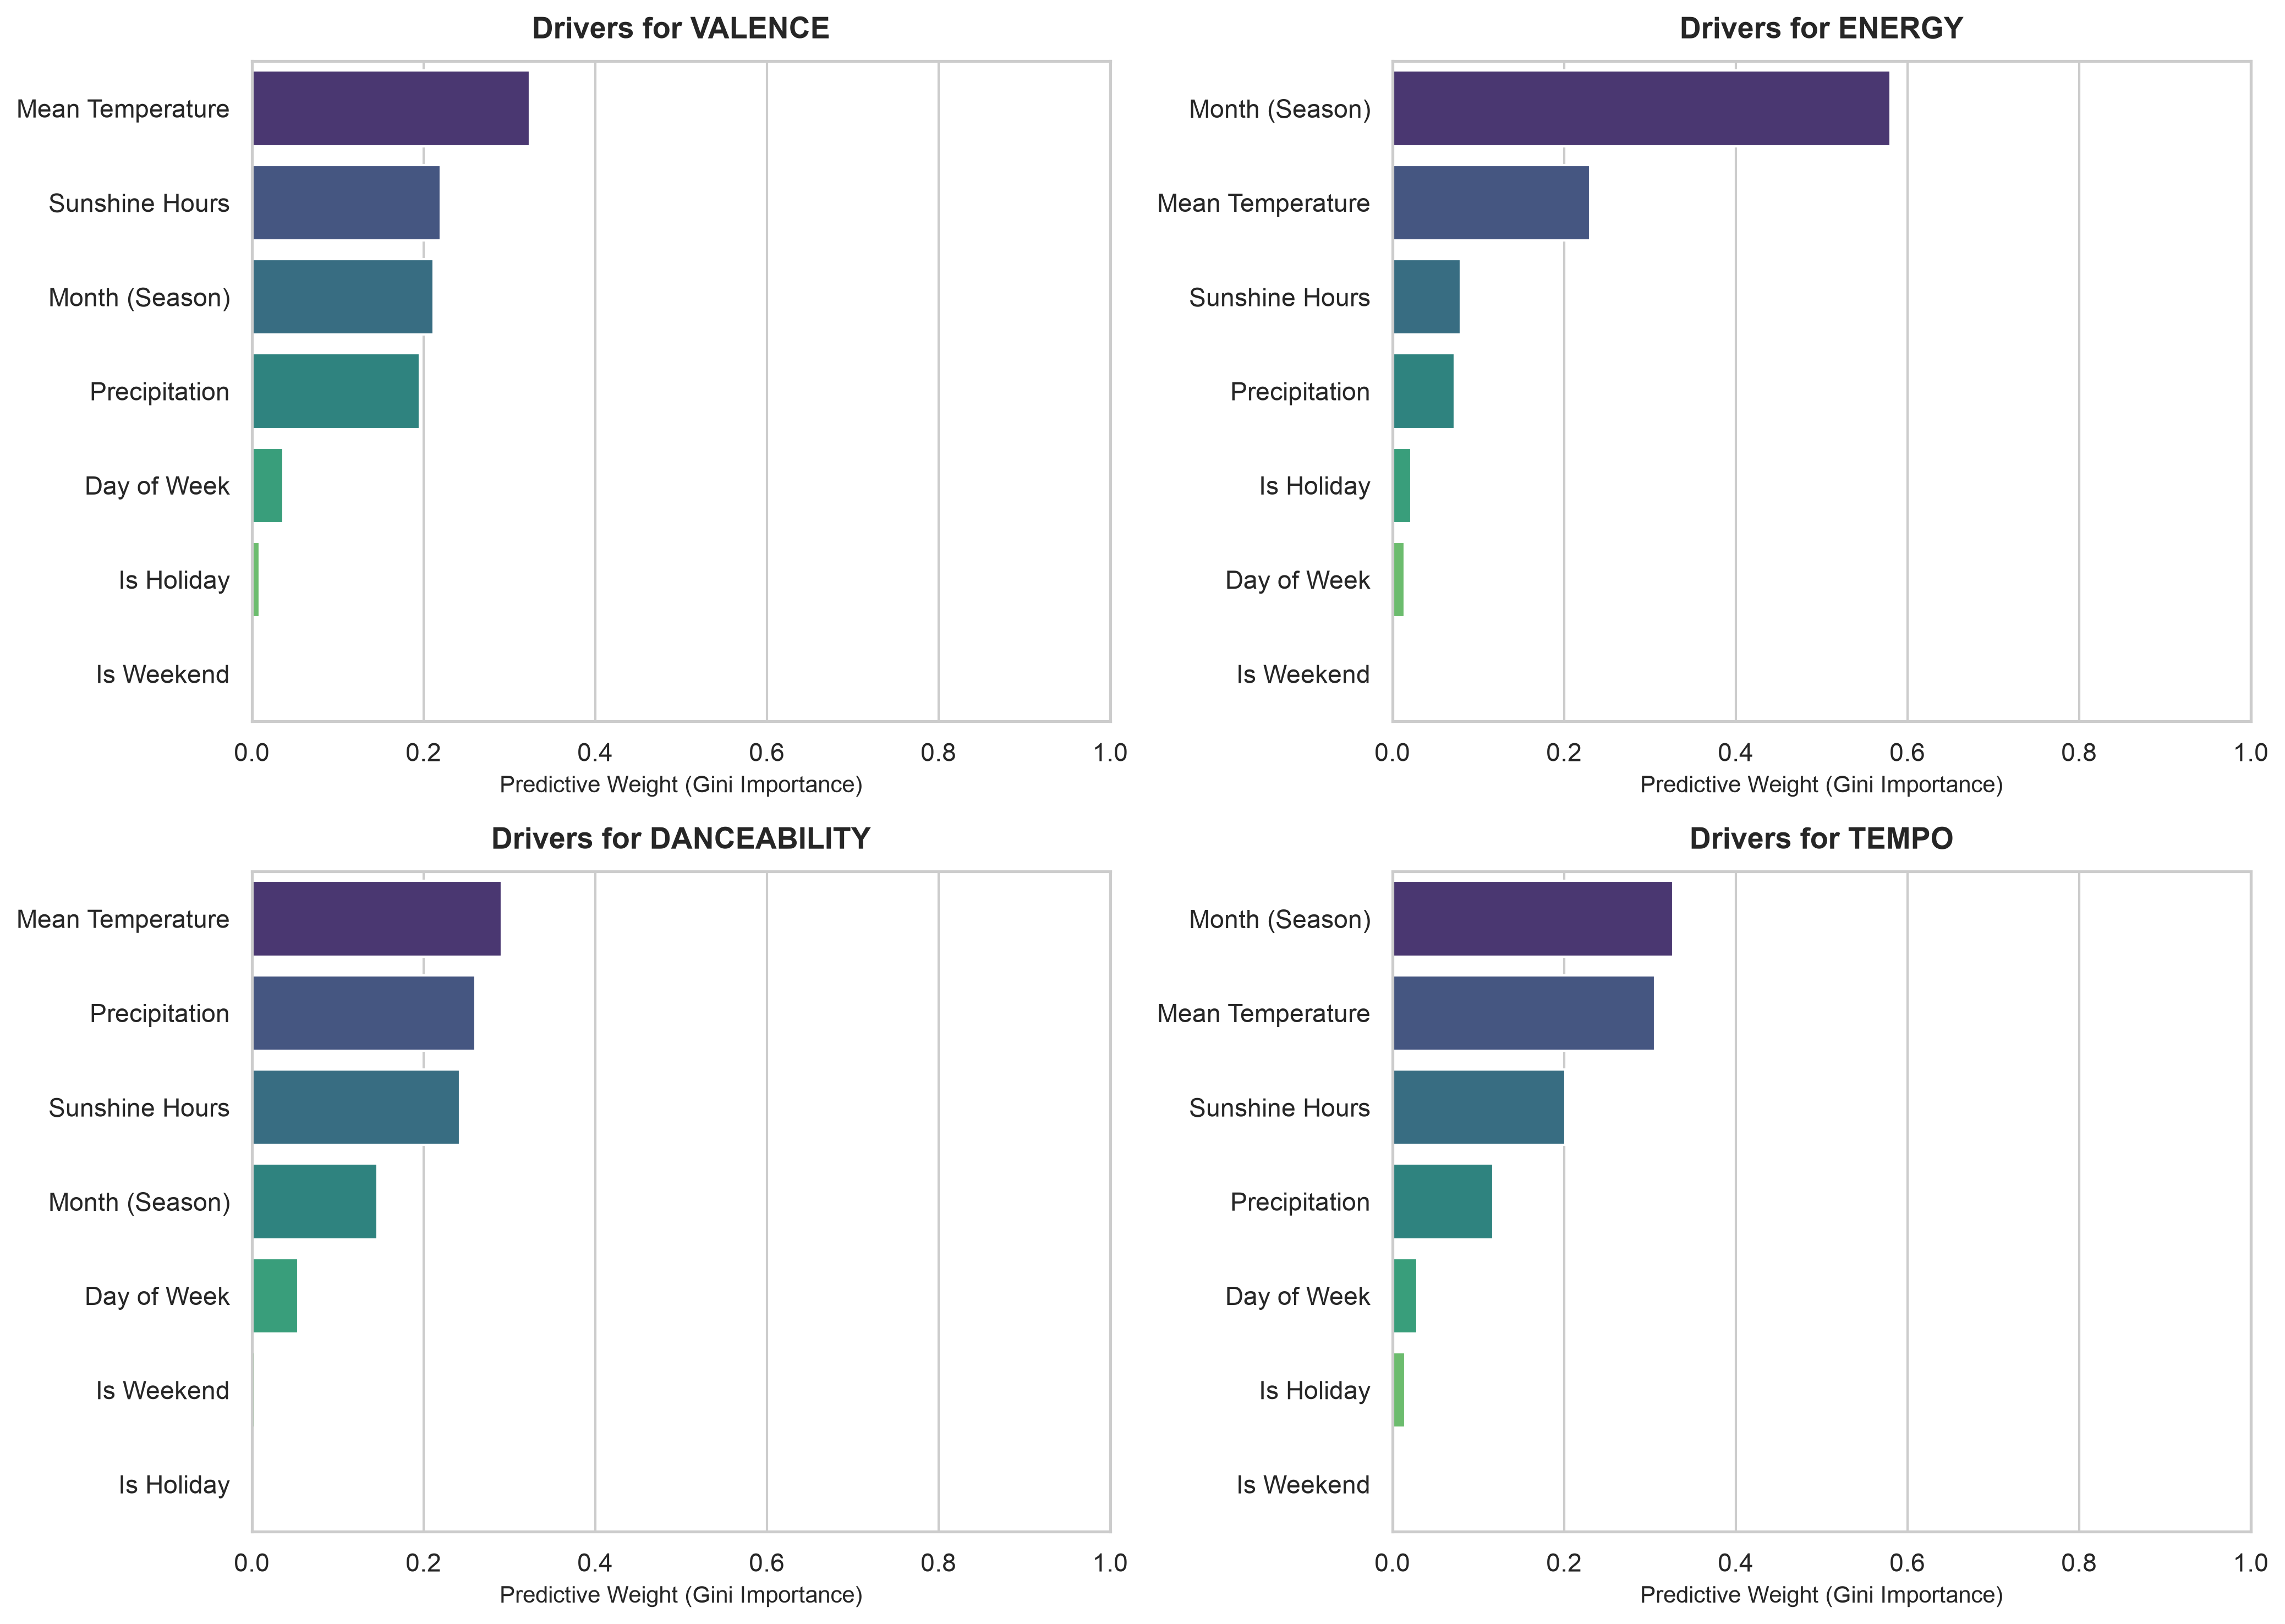

In [5]:
display(Image(filename=str(RESULTS / "feature_importances.png")))

**Top weather drivers (`random_forest_depth5` feature importances):**

- `avg_valence`: temperature (0.32), sunshine (0.22), month (0.21), precipitation (0.20) — fairly evenly spread.
- `avg_energy`: dominated by **month** (0.58), with temperature a distant second (0.23) — seasonality drives energy far more than daily weather does.
- `avg_danceability`: temperature (0.29), precipitation (0.26), sunshine (0.24), month (0.15) — the most balanced target, no single dominant driver.
- `avg_tempo`: month (0.33) and temperature (0.31) dominate, precipitation and sunshine contribute less.
- Across all four targets, `is_weekend`, `is_holiday`, and `day_of_week` are consistently the least important features — calendar/weather signal, not weekly rhythm, is what's doing the work.

## Recommendations

Top song recommendations for the current-weather scenario defined in `configuration_w7.yaml`, ranked by distance (in scaled valence/energy/danceability/tempo space) to the predicted mood profile.

In [7]:
recs = pd.read_csv(RESULTS / "song_recommendations.csv")
print(f"{len(recs)} recommended songs")
recs

1 recommended songs


,date,title,artist,rank,streams,trend,track_id,track_genre,danceability,energy,tempo,valence,acousticness,popularity,distance
0,2021-11-23,inf,Jaymes Young,86,98376.0,MOVE_UP,1SOClUWhOi8vHZYMz3GluK,pop,0.671,0.673,121.963,0.494,0.148,85.0,0.036608


## Findings

- **Best-performing model:** `random_forest_depth5` (mean R² = **0.1014** across the four mood targets) — the winning model type, but the low mean R² signals weather is a weak predictor overall.
- **Which moods are predictable:** `avg_energy` is by far the most weather-predictable target (R² ≈ 0.25–0.28 depending on model), while `avg_danceability` and `avg_tempo` are close to unpredictable from weather alone (R² near 0, even slightly negative for some model/target combinations, e.g. `random_forest_depth15` on tempo). `avg_valence` sits in between (R² ≈ 0.06–0.08).
- **Top weather drivers**: see the feature-importance breakdown above.
- **How the other models compare** (mean R² across all four targets):
  - `random_forest_depth15` — 0.090 (close second; actually beats the winner on `avg_valence`, 0.082 vs 0.068)
  - `hist_gradient_boosting` — 0.085 (also close behind)
  - `ridge` — 0.044 (clearly weakest — under half of any tree model, most visibly on `avg_danceability`: 0.015 vs 0.028–0.037 for the tree models)
  - **Takeaway:** the weak weather→mood relationship isn't well captured by a purely linear model (`ridge` lags every tree model), but extra tree depth doesn't help either — `random_forest_depth15` goes slightly *negative* on `avg_tempo` (−0.001), overfitting enough to underperform a flat mean baseline there, while the shallower `depth5` stays slightly positive.

## Takeaway

Weather predicts music mood only weakly in this dataset - `random_forest_depth5` was the best of the four model types tried, but its mean R² of 0.10 means weather explains a small share of day-to-day mood variation, concentrated almost entirely in `avg_energy` (largely via **month**, i.e. season) while `avg_tempo` and `avg_danceability` are essentially not predictable from weather alone. The song-recommendation step itself performs well - the top match for the sample cold/wet July scenario landed within ~0.04 distance of the predicted mood profile - so this pipeline is best read as a working **proof of concept** for weather-conditioned recommendation, not yet as evidence that weather is a strong driver of listening mood.